<a href="https://colab.research.google.com/github/Sirfowahid/Brain_Tumor_Segmentation_Using_UNET/blob/main/Week_07_UNet_from_Scratch_and_Image_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7: U-Net from Scratch & Image Segmentation 🧠🩻

Until now every model answered **one question per image**: "cat or dog?", "which tumor class?", "same person or not?". Segmentation asks a much harder one: **"what is every single pixel?"** Instead of a label, the model outputs a *mask* the same size as the input, outlining exactly where an object is.

This week we build the architecture that made this practical, the **U-Net** (Ronneberger et al., 2015), **completely from scratch**, and train it to outline **brain tumors in MRI scans**.

By the end of this notebook you will:
1. Explain the difference between **classification, detection, and segmentation**
2. Load an image + mask dataset and apply **joint augmentation** (the same flip/rotation to both image and mask)
3. Split medical data **by patient** (the Week 6 lesson applies here too, and matters even more)
4. Build every piece of a **U-Net**: double-conv blocks, the encoder, the decoder, and **skip connections**
5. Handle extreme **pixel-level class imbalance** with a combined **BCE + Dice loss**
6. Measure what matters: **Dice score and IoU** (and see why plain pixel accuracy is misleading)
7. Reuse Week 5 tools: `OneCycleLR` and **mixed precision**
8. Tune the prediction **threshold on validation**, then inspect successes, failures, and false alarms

> ⚠️ **Educational use only.** This is a classroom model trained on a small public research dataset. It is **not** a medical device and must never be used for diagnosis or treatment decisions.

## 0. Setup

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
from torchvision import tv_tensors
import torchvision.transforms.v2 as transforms_v2

import os
import re
import copy
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

print("PyTorch version:", torch.__version__)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
use_amp = (device.type == "cuda")   # mixed precision, same idea as Week 5
if not use_amp:
    print("⚠️ No GPU detected. Training will be slow. Enable one in Runtime > Change runtime type.")

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

PyTorch version: 2.14.1+cu130
Using device: cuda


## 1. What Is Segmentation?

| Task | Output | Example |
|---|---|---|
| **Classification** | one label per image | "this MRI slice contains a tumor" |
| **Detection** | boxes + labels | "a tumor is somewhere in this rectangle" |
| **Semantic segmentation** | **a label for every pixel** | "these exact pixels are tumor" |

Segmentation is just **classification applied to every pixel**. For our problem (tumor vs. not tumor) the model outputs, for each pixel, the probability that it belongs to a tumor, which is a **binary segmentation** problem. The same architecture handles many classes by outputting one channel per class.

### The core design problem
To decide whether a pixel is tumor, the network needs two things at once:
- **Context** ("what is this region? where am I in the brain?"), which needs a big receptive field, so we **downsample**
- **Precision** ("exactly where is the boundary?"), which needs fine spatial detail, which **downsampling destroys**

The U-Net's answer is elegant: do both, then **glue them together**.

```
 input ─► [enc 1] ───────────── skip ─────────────► [dec 1] ─► mask
              ↓ pool                                    ↑ upsample
           [enc 2] ───────────── skip ─────────► [dec 2]
              ↓ pool                                ↑ upsample
           [enc 3] ───────────── skip ─────► [dec 3]
              ↓ pool                            ↑ upsample
                      [ bottleneck ]
```

- The **encoder** (left side) repeatedly downsamples: big context, small resolution
- The **decoder** (right side) repeatedly upsamples back to full resolution
- **Skip connections** copy the high-resolution encoder features straight across to the decoder, handing it the fine detail that pooling threw away

The shape of the diagram is the "U" in the name.

## 2. Downloading the Dataset from Kaggle

**LGG MRI Segmentation** contains brain MRI slices from patients with lower-grade gliomas, each paired with a **manually drawn mask** of the FLAIR abnormality (the tumor region). The images are 256×256 with 3 channels (for most patients these are the pre-contrast, FLAIR, and post-contrast MRI sequences). Each patient contributes many slices.

Same Kaggle secret setup as previous weeks (`KAGGLE_API_TOKEN` in Colab Secrets).

In [ ]:
from google.colab import userdata

kaggle_token = userdata.get("KAGGLE_API_TOKEN")
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

!pip install -q kagglehub
import kagglehub

dataset_path = kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation")
print("Dataset downloaded to:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    if level <= 1:
        print("  " * level + os.path.basename(root) + "/")

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Dataset downloaded to: /kaggle/input/lgg-mri-segmentation
lgg-mri-segmentation/
  kaggle_3m/
  lgg-mri-segmentation/


### Pairing images with masks

Inside each patient folder, an image looks like `TCGA_..._12.tif` and its mask is `TCGA_..._12_mask.tif`. We build a `patient → [(image_path, mask_path), ...]` dictionary.

> 🔎 **Known quirk:** this Kaggle upload contains a **duplicate copy** of the whole dataset nested inside itself. If we're not careful, every patient would be loaded twice and (worse) could leak across splits. We keep only the **first** folder we find for each patient ID.

In [ ]:
def slice_number(filename):
    # "TCGA_CS_4941_19960909_12.tif" -> 12   (so slices sort in anatomical order, not alphabetically)
    return int(re.findall(r"_(\d+)(?:_mask)?\.tif$", filename.lower())[0])

patients = {}   # patient_id -> list of (image_path, mask_path)
for root, dirs, files in os.walk(dataset_path):
    tifs = [f for f in files if f.lower().endswith(".tif")]
    if not tifs:
        continue
    patient_id = os.path.basename(root)
    if patient_id in patients:
        continue                      # duplicate folder (packaging quirk): skip it
    file_set = set(files)
    pairs = []
    for f in sorted(tifs, key=slice_number):
        if f.lower().endswith("_mask.tif"):
            continue
        mask_name = f[:-4] + "_mask.tif"
        if mask_name in file_set:
            pairs.append((os.path.join(root, f), os.path.join(root, mask_name)))
    if pairs:
        patients[patient_id] = pairs

print(f"Patients: {len(patients)}")
print(f"Total image/mask pairs: {sum(len(v) for v in patients.values())}")
counts = [len(v) for v in patients.values()]
print(f"Slices per patient: min={min(counts)}, median={int(np.median(counts))}, max={max(counts)}")

Patients: 110
Total image/mask pairs: 3929
Slices per patient: min=20, median=33, max=88


### Loading everything into memory (downsampled)

The full 256×256 slices make training noticeably slower on a free GPU, so we downsample to `IMG_SIZE = 128`. This keeps the whole dataset in RAM (≈ 250 MB) and trains fast. Two details matter when resizing:

- Images use **bilinear** interpolation (smooth)
- Masks use **nearest-neighbor** interpolation, then get re-binarized. A mask must contain only 0 or 1; interpolating would create meaningless values like 0.37.

> 💡 You can set `IMG_SIZE = 256` for full resolution. Small tumors keep more detail, but everything runs ~4× slower.

In [ ]:
IMG_SIZE = 128

def load_slice(img_path, mask_path, size):
    img = Image.open(img_path).convert("RGB").resize((size, size), Image.Resampling.BILINEAR)
    mask = Image.open(mask_path).convert("L").resize((size, size), Image.Resampling.NEAREST)
    img = np.array(img).transpose(2, 0, 1)             # (H,W,3) -> (3,H,W), uint8
    mask = (np.array(mask) > 127).astype(np.uint8)     # binarize: 0 = background, 1 = tumor
    return img, mask

patient_ids = sorted(patients.keys())
X_list, Y_list, slice_patient = [], [], []
for pid in tqdm(patient_ids, desc="Loading patients"):
    for img_path, mask_path in patients[pid]:
        img, mask = load_slice(img_path, mask_path, IMG_SIZE)
        X_list.append(img); Y_list.append(mask); slice_patient.append(pid)

X = np.stack(X_list)                      # (N, 3, H, W) uint8
Y = np.stack(Y_list)                      # (N, H, W)    uint8 in {0,1}
slice_patient = np.array(slice_patient)   # patient id of every slice
del X_list, Y_list

print("Images:", X.shape, X.dtype, "| Masks:", Y.shape, Y.dtype, "| unique mask values:", np.unique(Y))

Loading patients:   0%|          | 0/110 [00:00<?, ?it/s]

Images: (3929, 3, 128, 128) uint8 | Masks: (3929, 128, 128) uint8 | unique mask values: [0 1]


### Look at the data and the imbalance

Two facts about this dataset shape every decision we make from here:
1. **Many slices contain no tumor at all** (top and bottom of the head, for instance)
2. Even in slices that do, the tumor is a **tiny fraction of the pixels**

Slices with a tumor:     1373  (34.9%)
Slices without a tumor:  2556  (65.1%)
Tumor pixels, over ALL pixels:               1.03%
Tumor pixels, within tumor-containing slices: 2.95%

⚠️ A model that predicts 'background' for EVERY pixel would be 99.0% 'accurate'... and completely useless.


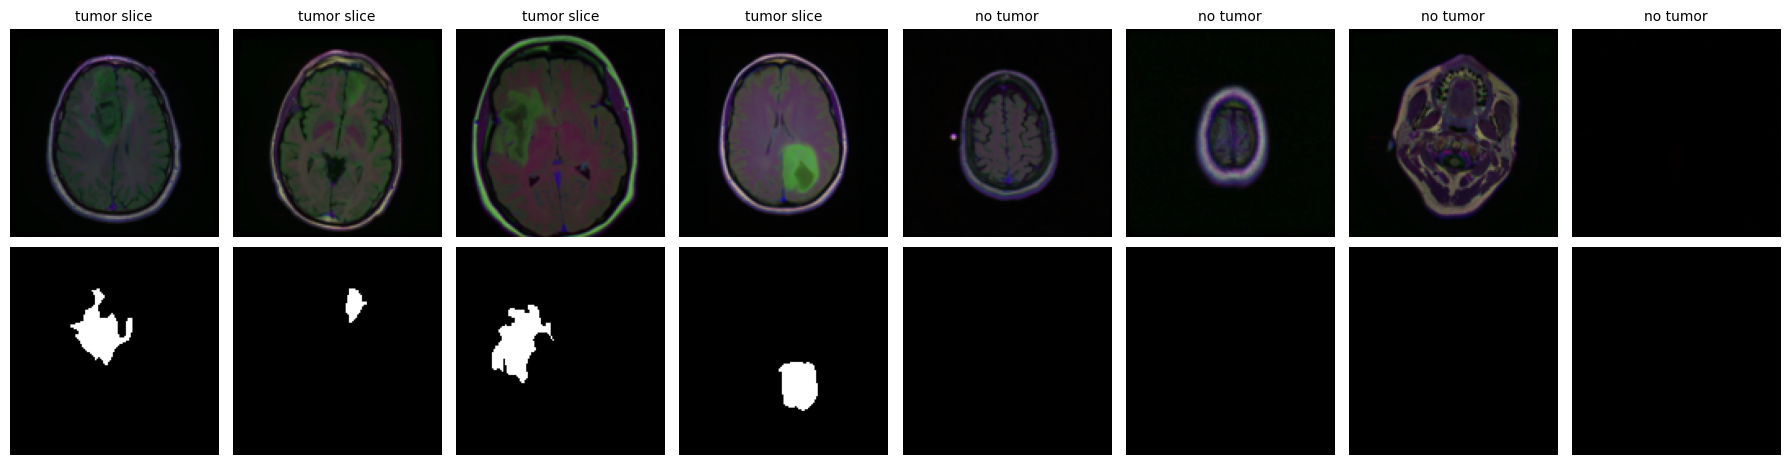

In [ ]:
N = len(X)
has_tumor = Y.reshape(N, -1).max(axis=1) > 0

print(f"Slices with a tumor:    {has_tumor.sum():5d}  ({has_tumor.mean()*100:.1f}%)")
print(f"Slices without a tumor: {(~has_tumor).sum():5d}  ({(~has_tumor).mean()*100:.1f}%)")
print(f"Tumor pixels, over ALL pixels:               {Y.mean()*100:.2f}%")
print(f"Tumor pixels, within tumor-containing slices: {Y[has_tumor].mean()*100:.2f}%")
print(f"\n⚠️ A model that predicts 'background' for EVERY pixel would be {100*(1-Y.mean()):.1f}% 'accurate'... and completely useless.")

rng = np.random.default_rng(SEED)
pos_examples = rng.choice(np.where(has_tumor)[0], 4, replace=False)
neg_examples = rng.choice(np.where(~has_tumor)[0], 4, replace=False)

fig, axes = plt.subplots(2, 8, figsize=(18, 4.8))
for k, idx in enumerate(list(pos_examples) + list(neg_examples)):
    row, col = divmod(k, 4)
    axes[0, k].imshow(X[idx].transpose(1, 2, 0)); axes[0, k].axis("off")
    axes[0, k].set_title("tumor slice" if has_tumor[idx] else "no tumor", fontsize=10)
    axes[1, k].imshow(Y[idx], cmap="gray", vmin=0, vmax=1); axes[1, k].axis("off")
axes[0, 0].set_ylabel("MRI"); axes[1, 0].set_ylabel("mask")
plt.tight_layout()
plt.show()

## 3. Splitting by **Patient**, Not by Slice ⚠️

Last week we split by *identity*. Same principle here, with higher stakes. Neighbouring slices from the **same patient** are almost identical (same skull, same tumor, shifted by a millimetre or two). If slice 12 is in training and slice 13 is in validation, the model is essentially being tested on something it already studied, and your Dice score will look wonderful and mean nothing.

> **Rule: every slice of a given patient must land in exactly one split.**

We use roughly **70% / 15% / 15%** of *patients* for train / validation / test.

In [ ]:
rng = random.Random(SEED)
shuffled_patients = patient_ids[:]
rng.shuffle(shuffled_patients)

n_patients = len(shuffled_patients)
n_train = int(0.70 * n_patients)
n_val   = int(0.15 * n_patients)

train_patients = shuffled_patients[:n_train]
val_patients   = shuffled_patients[n_train:n_train + n_val]
test_patients  = shuffled_patients[n_train + n_val:]

# Safety check: no patient in more than one split
assert not (set(train_patients) & set(val_patients))
assert not (set(train_patients) & set(test_patients))
assert not (set(val_patients) & set(test_patients))

train_idx = np.where(np.isin(slice_patient, train_patients))[0]
val_idx   = np.where(np.isin(slice_patient, val_patients))[0]
test_idx  = np.where(np.isin(slice_patient, test_patients))[0]

for name, pats, idx in [("Train", train_patients, train_idx), ("Val", val_patients, val_idx), ("Test", test_patients, test_idx)]:
    print(f"{name:<6} {len(pats):3d} patients | {len(idx):5d} slices | {has_tumor[idx].mean()*100:.1f}% contain tumor")

Train   77 patients |  2719 slices | 34.4% contain tumor
Val     16 patients |   621 slices | 33.7% contain tumor
Test    17 patients |   589 slices | 39.0% contain tumor


## 4. Dataset & Joint Augmentation

### The segmentation augmentation rule
In classification, flipping an image only changes the image. In segmentation, **the mask must be transformed identically**. If we flip the MRI but not the mask, the labels no longer line up with the pixels.

`torchvision.transforms.v2` (introduced in Week 5) handles this natively. If you wrap the image as `tv_tensors.Image` and the mask as `tv_tensors.Mask` and pass **both** into the transform, then:
- **Geometric** transforms (flip, rotate, translate, scale) are applied **identically to both**. Masks automatically use nearest-neighbor interpolation, so they stay strictly 0/1.
- **Photometric** transforms (`ColorJitter`, `Normalize`) are applied to the **image only**. Masks are left alone.

### Normalization
We're training from scratch (no ImageNet weights), so ImageNet's mean/std isn't special. We compute the **per-channel mean and std from the training slices only** (computing them on val/test data would be a subtle form of leakage).

In [ ]:
# Per-channel mean/std from TRAIN slices only, computed in chunks to keep memory low
sum_c = np.zeros(3, dtype=np.float64); sumsq_c = np.zeros(3, dtype=np.float64); n_pix = 0
for start in range(0, len(train_idx), 256):
    chunk = X[train_idx[start:start + 256]].astype(np.float64) / 255.0       # (B,3,H,W)
    sum_c += chunk.sum(axis=(0, 2, 3))
    sumsq_c += (chunk ** 2).sum(axis=(0, 2, 3))
    n_pix += chunk.shape[0] * chunk.shape[2] * chunk.shape[3]

CH_MEAN = (sum_c / n_pix).tolist()
CH_STD  = np.sqrt(sumsq_c / n_pix - (sum_c / n_pix) ** 2).tolist()
print("Channel mean:", np.round(CH_MEAN, 4))
print("Channel std: ", np.round(CH_STD, 4))

Channel mean: [0.0933 0.0839 0.086 ]
Channel std:  [0.131  0.1194 0.1232]


In [ ]:
train_transform = transforms_v2.Compose([
    transforms_v2.RandomHorizontalFlip(p=0.5),                                            # image AND mask
    transforms_v2.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)),      # image AND mask (mask: nearest)
    transforms_v2.ColorJitter(brightness=0.2, contrast=0.2),                              # image ONLY
    transforms_v2.ToDtype(torch.float32, scale=True),                                     # image only: uint8 -> float 0..1
    transforms_v2.Normalize(mean=CH_MEAN, std=CH_STD),                                    # image only
])

eval_transform = transforms_v2.Compose([
    transforms_v2.ToDtype(torch.float32, scale=True),
    transforms_v2.Normalize(mean=CH_MEAN, std=CH_STD),
])


class SegmentationDataset(Dataset):
    # Holds uint8 arrays already in memory; wraps each sample as tv_tensors so transforms know which is which.
    def __init__(self, images, masks, indices, transform):
        self.images, self.masks = images, masks
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        g = self.indices[i]
        image = tv_tensors.Image(torch.from_numpy(self.images[g]))                    # (3,H,W) uint8
        mask = tv_tensors.Mask(torch.from_numpy(self.masks[g]).unsqueeze(0))          # (1,H,W) uint8
        image, mask = self.transform(image, mask)
        # back to plain tensors (drop the tv_tensor wrappers); mask becomes float for the loss
        return image.as_subclass(torch.Tensor), mask.as_subclass(torch.Tensor).float()


BATCH_SIZE = 32
train_ds = SegmentationDataset(X, Y, train_idx, train_transform)
val_ds   = SegmentationDataset(X, Y, val_idx,   eval_transform)
test_ds  = SegmentationDataset(X, Y, test_idx,  eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_ds)}  Val: {len(val_ds)}  Test: {len(test_ds)}")

Train: 2719  Val: 621  Test: 589


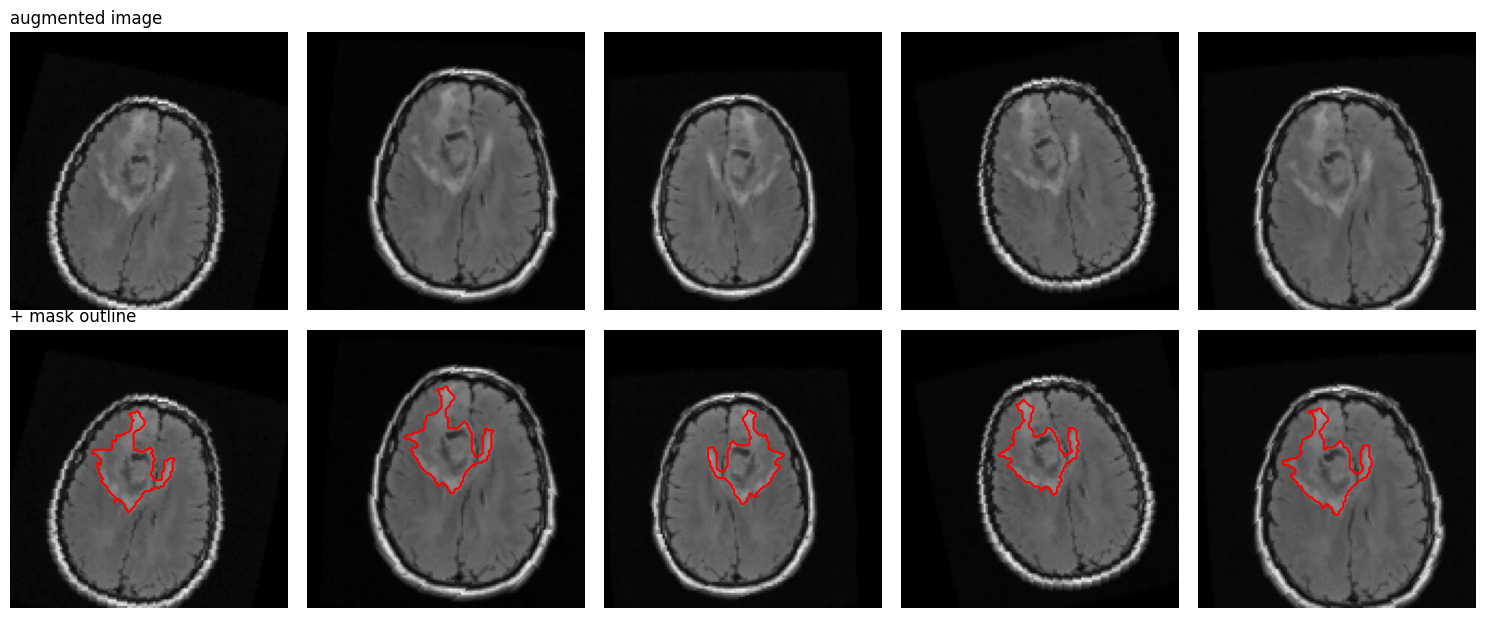

In [ ]:
# PROOF that image and mask are transformed together: same tumor slice, 5 random augmentations.
# The red outline of the mask must hug the same anatomy every time.
demo_ds = SegmentationDataset(X, Y, [pos_examples[0]] * 5, train_transform)

fig, axes = plt.subplots(2, 5, figsize=(15, 6.2))
for k in range(5):
    img, msk = demo_ds[k]
    axes[0, k].imshow(img[1], cmap="gray"); axes[0, k].axis("off")
    axes[1, k].imshow(img[1], cmap="gray")
    axes[1, k].contour(msk[0].numpy(), levels=[0.5], colors="red", linewidths=1.5); axes[1, k].axis("off")
axes[0, 0].set_title("augmented image", loc="left"); axes[1, 0].set_title("+ mask outline", loc="left")
plt.tight_layout()
plt.show()

## 5. Building the U-Net From Scratch

We build it bottom-up from three small pieces.

### Piece 1: `DoubleConv`
The basic repeated unit: **two** 3×3 convolutions, each followed by BatchNorm and ReLU. (The original paper had no BatchNorm; it didn't exist yet. Adding it makes training from scratch far more stable.) We use `padding=1` so each convolution **preserves** the spatial size. The original paper used unpadded convolutions that shrink the map and force you to crop skip connections; padding is the common modern simplification.

### Piece 2: `Down` (encoder step)
`MaxPool2d(2)` halves the height and width, then a `DoubleConv` **doubles the channels**. The network trades spatial resolution for richer features.

### Piece 3: `Up` (decoder step)
1. A **transposed convolution** (`ConvTranspose2d`, stride 2) learns to **double** the height and width and halve the channels
2. **Concatenate** with the matching encoder feature map (the **skip connection**) along the channel dimension
3. A `DoubleConv` fuses the two sources

Finally, a **1×1 convolution** maps the last features to the output channels (1 for us: the tumor logit per pixel). We output raw **logits** (no sigmoid) because our loss applies the sigmoid itself, in a numerically stable way.

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),   # bias unnecessary: BatchNorm follows
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    # halve the resolution, then extract features at the coarser scale
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool_conv = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))

    def forward(self, x):
        return self.pool_conv(x)


class Up(nn.Module):
    # double the resolution, merge with the skip connection, then fuse
    def __init__(self, in_ch, out_ch, use_skips=True):
        super().__init__()
        self.use_skips = use_skips
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        # after concatenation: (in_ch // 2) from the upsampled path + (in_ch // 2) from the skip = in_ch
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        # If H or W were odd before pooling, shapes can be off by 1 pixel; pad to match
        diff_h, diff_w = skip.size(2) - x.size(2), skip.size(3) - x.size(3)
        if diff_h != 0 or diff_w != 0:
            x = F.pad(x, [diff_w // 2, diff_w - diff_w // 2, diff_h // 2, diff_h - diff_h // 2])
        if not self.use_skips:
            skip = torch.zeros_like(skip)      # ablation switch: keeps shapes identical but removes the information
        return self.conv(torch.cat([skip, x], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels=3, n_classes=1, base=32, use_skips=True):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]      # channels per level: 32, 64, 128, 256, 512

        # Encoder (contracting path)
        self.inc   = DoubleConv(in_channels, c[0])
        self.down1 = Down(c[0], c[1])
        self.down2 = Down(c[1], c[2])
        self.down3 = Down(c[2], c[3])
        self.down4 = Down(c[3], c[4])                            # bottleneck: smallest resolution, most channels

        # Decoder (expanding path)
        self.up1 = Up(c[4], c[3], use_skips)
        self.up2 = Up(c[3], c[2], use_skips)
        self.up3 = Up(c[2], c[1], use_skips)
        self.up4 = Up(c[1], c[0], use_skips)

        self.outc = nn.Conv2d(c[0], n_classes, kernel_size=1)    # 1x1 conv -> one logit per pixel

    def forward(self, x):
        x1 = self.inc(x)        # full resolution
        x2 = self.down1(x1)     # 1/2
        x3 = self.down2(x2)     # 1/4
        x4 = self.down3(x3)     # 1/8
        x5 = self.down4(x4)     # 1/16  (bottleneck)

        x = self.up1(x5, x4)    # skip connections: each decoder stage receives the
        x = self.up2(x, x3)     # encoder features from the SAME resolution level
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)     # raw logits, shape (B, n_classes, H, W)


model = UNet(in_channels=3, n_classes=1, base=32).to(device)
print(f"U-Net parameters: {sum(p.numel() for p in model.parameters()):,}")

U-Net parameters: 7,763,041


In [ ]:
# Trace the tensor shape after every stage, so you can SEE the U: shrink, bottleneck, grow back.
shapes = {}
hooks = [m.register_forward_hook(lambda m_, inp, out, name=name: shapes.__setitem__(name, tuple(out.shape)))
         for name, m in model.named_children()]

model.eval()
with torch.no_grad():
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(device)
    out = model(dummy)
for h in hooks:
    h.remove()

print(f"{'stage':<8}{'output shape (B, C, H, W)':<28}")
print("-" * 36)
print(f"{'input':<8}{str(tuple(dummy.shape)):<28}")
for name, shp in shapes.items():
    print(f"{name:<8}{str(shp):<28}")

assert out.shape == (1, 1, IMG_SIZE, IMG_SIZE), "Output mask must match the input's height and width!"

stage   output shape (B, C, H, W)   
------------------------------------
input   (1, 3, 128, 128)            
inc     (1, 32, 128, 128)           
down1   (1, 64, 64, 64)             
down2   (1, 128, 32, 32)            
down3   (1, 256, 16, 16)            
down4   (1, 512, 8, 8)              
up1     (1, 256, 16, 16)            
up2     (1, 128, 32, 32)            
up3     (1, 64, 64, 64)             
up4     (1, 32, 128, 128)           
outc    (1, 1, 128, 128)            


## 6. Loss Function: BCE + Dice

### Why plain cross-entropy struggles here
With ~1–2% tumor pixels, **Binary Cross-Entropy (BCE)** averaged over all pixels can be minimized to a respectable-looking value by predicting "background" nearly everywhere. The tumor pixels contribute a tiny share of the total loss.

### Dice loss
The **Dice coefficient** measures *overlap* between the prediction `P` and ground truth `T`:

```
Dice = 2 · |P ∩ T| / (|P| + |T|)          (1 = perfect overlap, 0 = no overlap)
```

Dice only cares about the tumor region, not the vast background, so class imbalance matters much less. To use it as a loss we need it to be differentiable, so instead of hard 0/1 predictions we plug in the **soft probabilities** from the sigmoid:

```
DiceLoss = 1 − (2·Σ(p·t) + smooth) / (Σp + Σt + smooth)
```

The small `smooth` term avoids dividing by zero on slices with no tumor (if the model also predicts nothing, the Dice is 1, which is correct).

### The combination
**BCE** gives smooth, stable per-pixel gradients early in training. **Dice** directly optimizes the overlap we actually care about. Using both is a very common, reliable recipe.

In [ ]:
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, smooth=1.0):
        super().__init__()
        self.bce_weight = bce_weight
        self.smooth = smooth

    def forward(self, logits, targets):
        logits = logits.float()                                   # compute the loss in fp32 even under mixed precision
        bce = F.binary_cross_entropy_with_logits(logits, targets)

        probs = torch.sigmoid(logits)
        inter = (probs * targets).sum(dim=(1, 2, 3))              # per-image overlap
        denom = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
        dice = (2 * inter + self.smooth) / (denom + self.smooth)
        dice_loss = 1 - dice.mean()                               # average over the batch

        return self.bce_weight * bce + (1 - self.bce_weight) * dice_loss


# Sanity check with a tiny hand-made example: 8x8 image, a 3x3 "tumor" in the middle
target = torch.zeros(1, 1, 8, 8); target[0, 0, 2:5, 2:5] = 1
perfect    = (target * 2 - 1) * 20            # confident, correct logits
all_bg     = torch.full_like(target, -20.0)   # "no tumor anywhere"
all_tumor  = torch.full_like(target, 20.0)    # "tumor everywhere"

crit = BCEDiceLoss()
print(f"Perfect prediction: {crit(perfect, target).item():.4f}   (≈ 0)")
print(f"All background:     {crit(all_bg, target).item():.4f}   (Dice term punishes missing the tumor)")
print(f"All tumor:          {crit(all_tumor, target).item():.4f}   (also punished)")

Perfect prediction: 0.0000   (≈ 0)
All background:     1.8563   (Dice term punishes missing the tumor)
All tumor:          8.9654   (also punished)


## 7. Metrics: Dice, IoU, and Why Accuracy Lies

| Metric | Formula | Meaning |
|---|---|---|
| **Pixel accuracy** | correct pixels / all pixels | ❌ Misleading here (dominated by background) |
| **Dice** (F1 on pixels) | `2·TP / (2·TP + FP + FN)` | Overlap of prediction and truth |
| **IoU** (Jaccard) | `TP / (TP + FP + FN)` | Stricter overlap measure; `IoU = Dice / (2 − Dice)` |

We'll report several views of the same predictions, because each answers a different question:
- **Dataset Dice / IoU**: pools every pixel of every slice (large tumors weigh more)
- **Tumor-slice Dice / IoU**: the *average per-slice* score over slices that really contain a tumor (every slice counts equally; small tumors matter as much as big ones)
- **False-alarm rate**: of the tumor-free slices, how many does the model wrongly flag (≥ `MIN_AREA` predicted pixels)?

We compute metrics from probabilities plus a **threshold** (default 0.5), because the threshold is something we can tune on validation (Section 9).

In [ ]:
MIN_AREA = 10   # a tumor-free slice counts as a "false alarm" if the model predicts at least this many tumor pixels

@torch.no_grad()
def predict(model, loader, criterion=None):
    # Runs the model over a loader. Returns (probabilities, masks, mean loss or None) as CPU tensors.
    model.eval()
    all_probs, all_masks = [], []
    total_loss, n = 0.0, 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        with autocast(device_type=device.type, enabled=use_amp):
            logits = model(images)
        if criterion is not None:
            total_loss += criterion(logits, masks).item() * images.size(0)
            n += images.size(0)
        all_probs.append(torch.sigmoid(logits.float()).cpu())
        all_masks.append(masks.cpu())
    mean_loss = total_loss / n if criterion is not None else None
    return torch.cat(all_probs), torch.cat(all_masks), mean_loss


def per_slice_stats(probs, masks, threshold=0.5):
    # Per-slice intersection / predicted area / true area (each a tensor of shape (num_slices,))
    pred = (probs > threshold).float()
    inter = (pred * masks).sum(dim=(1, 2, 3))
    pred_area = pred.sum(dim=(1, 2, 3))
    true_area = masks.sum(dim=(1, 2, 3))
    return inter, pred_area, true_area


def compute_metrics(probs, masks, threshold=0.5):
    inter, p, t = per_slice_stats(probs, masks, threshold)
    union = p + t - inter
    has_t = t > 0

    out = {
        "pixel_acc": ((probs > threshold).float() == masks).float().mean().item(),
        "dice": (2 * inter.sum() / (p.sum() + t.sum() + 1e-8)).item(),         # pooled over all pixels
        "iou":  (inter.sum() / (union.sum() + 1e-8)).item(),
    }
    out["slice_dice"] = (2 * inter[has_t] / (p[has_t] + t[has_t])).mean().item() if has_t.any() else float("nan")
    out["slice_iou"]  = (inter[has_t] / union[has_t]).mean().item() if has_t.any() else float("nan")
    out["false_alarm"] = (p[~has_t] >= MIN_AREA).float().mean().item() if (~has_t).any() else float("nan")
    return out

## 8. Training

Putting Week 5's toolkit to work:
- **`AdamW`** optimizer with **`OneCycleLR`** (stepped once per **batch**), which usually converges fast and is a strong default for training from scratch
- **Mixed precision** (`autocast` + `GradScaler`) for speed and lower memory on GPU
- **Best-epoch checkpointing**: after each epoch we evaluate on the **validation patients** and keep the weights with the best validation Dice

> ⏱️ On a free Colab T4 at `IMG_SIZE=128`, each epoch should take on the order of seconds to a minute. On CPU it will be painfully slow.

In [ ]:
def train_unet(model, train_loader, val_loader, num_epochs=20, max_lr=1e-3):
    criterion = BCEDiceLoss()
    optimizer = optim.AdamW(model.parameters(), lr=max_lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=max_lr, total_steps=num_epochs * len(train_loader)
    )
    scaler = GradScaler(enabled=use_amp)

    history = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": [], "val_slice_dice": []}
    best_dice, best_state = -1.0, None
    start = time.time()

    for epoch in range(num_epochs):
        model.train()
        running, n_seen = 0.0, 0
        for images, masks in train_loader:
            images, masks = images.to(device), masks.to(device)

            optimizer.zero_grad()
            with autocast(device_type=device.type, enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, masks)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()                      # OneCycleLR steps every BATCH (Week 5)

            running += loss.item() * images.size(0)
            n_seen += images.size(0)

        train_loss = running / n_seen
        probs, vmasks, val_loss = predict(model, val_loader, criterion)
        m = compute_metrics(probs, vmasks, threshold=0.5)

        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
        history["val_dice"].append(m["dice"]); history["val_iou"].append(m["iou"])
        history["val_slice_dice"].append(m["slice_dice"])

        star = ""
        if m["dice"] > best_dice:
            best_dice, best_state = m["dice"], copy.deepcopy(model.state_dict())
            star = "  ⭐ best so far"
        print(f"Epoch [{epoch+1:2d}/{num_epochs}]  Train Loss: {train_loss:.4f}  Val Loss: {val_loss:.4f}  "
              f"Val Dice: {m['dice']:.4f}  Val IoU: {m['iou']:.4f}{star}")

    model.load_state_dict(best_state)             # restore the best epoch, not necessarily the last
    history["train_time_sec"] = time.time() - start
    return model, history

In [ ]:
set_seed()
model = UNet(in_channels=3, n_classes=1, base=32).to(device)
model, history = train_unet(model, train_loader, val_loader, num_epochs=4, max_lr=1e-3)
print(f"\nTraining complete! ✅  ({history['train_time_sec']:.0f} seconds)")

Epoch [ 1/4]  Train Loss: 0.7503  Val Loss: 0.6721  Val Dice: 0.0060  Val IoU: 0.0030  ⭐ best so far
Epoch [ 2/4]  Train Loss: 0.5976  Val Loss: 0.5718  Val Dice: 0.6337  Val IoU: 0.4638  ⭐ best so far
Epoch [ 3/4]  Train Loss: 0.5212  Val Loss: 0.5014  Val Dice: 0.6885  Val IoU: 0.5250  ⭐ best so far
Epoch [ 4/4]  Train Loss: 0.4901  Val Loss: 0.4869  Val Dice: 0.7284  Val IoU: 0.5728  ⭐ best so far

Training complete! ✅  (41 seconds)


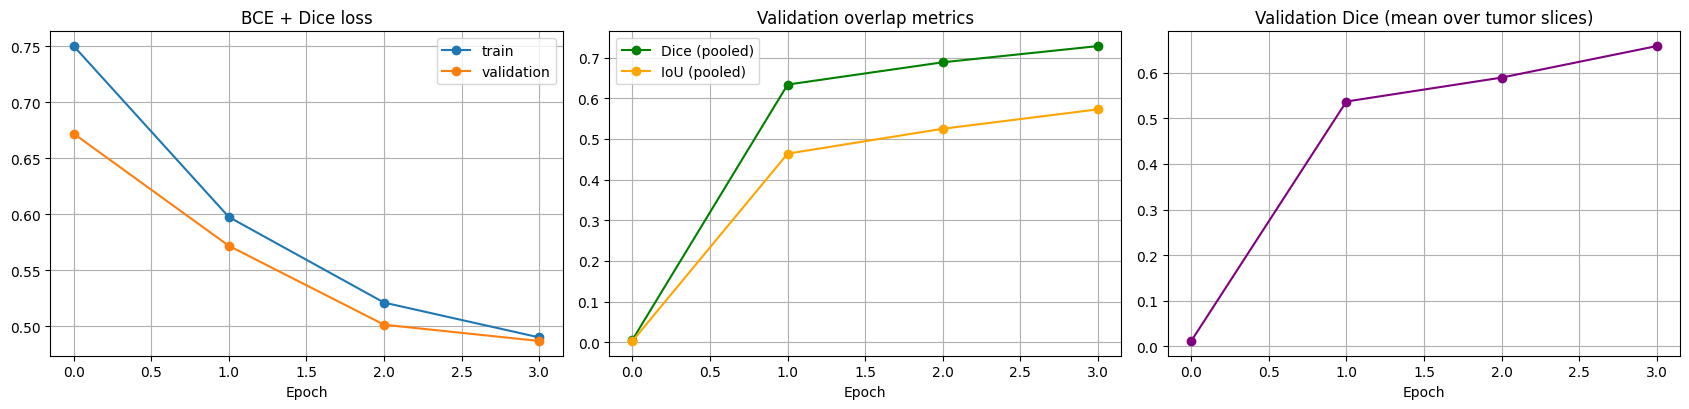

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(history["train_loss"], marker="o", label="train")
axes[0].plot(history["val_loss"], marker="o", label="validation")
axes[0].set_title("BCE + Dice loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(True)

axes[1].plot(history["val_dice"], marker="o", color="green", label="Dice (pooled)")
axes[1].plot(history["val_iou"], marker="o", color="orange", label="IoU (pooled)")
axes[1].set_title("Validation overlap metrics"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(True)

axes[2].plot(history["val_slice_dice"], marker="o", color="purple")
axes[2].set_title("Validation Dice (mean over tumor slices)"); axes[2].set_xlabel("Epoch"); axes[2].grid(True)
plt.tight_layout()
plt.show()

## 9. Choosing the Threshold & Final Evaluation on Unseen Patients

The model outputs a *probability* for each pixel. Turning that into a mask needs a **threshold**. 0.5 is a default, not a law; because tumor pixels are rare, a different cutoff can give better overlap.

Same discipline as Week 6: **pick the threshold on validation patients, report on test patients using that threshold.** Never tune on the test set.

In [ ]:
val_probs, val_masks, _ = predict(model, val_loader)

print(f"{'threshold':>10}{'val Dice':>12}{'val IoU':>12}{'tumor-slice Dice':>20}{'false alarms':>15}")
print("-" * 69)
best_thr, best_val_dice = 0.5, -1
for thr in np.arange(0.1, 0.91, 0.1):
    m = compute_metrics(val_probs, val_masks, thr)
    print(f"{thr:>10.1f}{m['dice']:>12.4f}{m['iou']:>12.4f}{m['slice_dice']:>20.4f}{m['false_alarm']*100:>14.1f}%")
    if m["dice"] > best_val_dice:
        best_thr, best_val_dice = float(thr), m["dice"]
print(f"\nChosen threshold (best validation Dice): {best_thr:.1f}")

 threshold    val Dice     val IoU    tumor-slice Dice   false alarms
---------------------------------------------------------------------
       0.1      0.0311      0.0158              0.4730         100.0%
       0.2      0.6281      0.4579              0.6424          90.5%
       0.3      0.6982      0.5363              0.6549          29.9%
       0.4      0.7155      0.5570              0.6575          26.0%
       0.5      0.7284      0.5728              0.6584          21.8%
       0.6      0.7419      0.5897              0.6544          17.0%
       0.7      0.7525      0.6032              0.6412          13.1%
       0.8      0.7484      0.5980              0.6227           6.8%
       0.9      0.7223      0.5653              0.5876           5.8%

Chosen threshold (best validation Dice): 0.7


In [ ]:
test_probs, test_masks, _ = predict(model, test_loader)
m = compute_metrics(test_probs, test_masks, best_thr)

# Baseline for comparison: a "model" that predicts background for every pixel
bg_acc = 1 - test_masks.mean().item()

print(f"TEST patients: {len(test_patients)}  |  slices: {len(test_ds)}  |  threshold: {best_thr:.1f}")
print("-" * 58)
print(f"Pixel accuracy:               {m['pixel_acc']*100:6.2f}%   (all-background 'model': {bg_acc*100:.2f}%  <- why accuracy lies!)")
print(f"Dice (pooled):                {m['dice']:6.4f}   (all-background: 0.0000)")
print(f"IoU  (pooled):                {m['iou']:6.4f}")
print(f"Dice (mean over tumor slices):{m['slice_dice']:6.4f}")
print(f"IoU  (mean over tumor slices):{m['slice_iou']:6.4f}")
print(f"False-alarm rate on tumor-free slices: {m['false_alarm']*100:.1f}%")

TEST patients: 17  |  slices: 589  |  threshold: 0.7
----------------------------------------------------------
Pixel accuracy:                99.46%   (all-background 'model': 98.98%  <- why accuracy lies!)
Dice (pooled):                0.7481   (all-background: 0.0000)
IoU  (pooled):                0.5976
Dice (mean over tumor slices):0.6076
IoU  (mean over tumor slices):0.5153
False-alarm rate on tumor-free slices: 18.7%


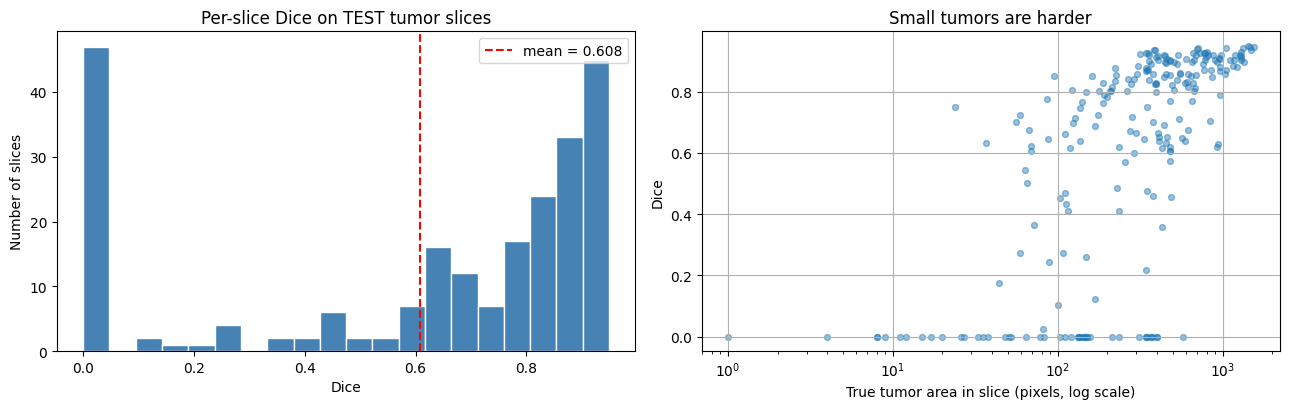

In [ ]:
# How consistent is the model? Per-slice Dice distribution over slices that truly contain a tumor
inter, p_area, t_area = per_slice_stats(test_probs, test_masks, best_thr)
pos = (t_area > 0)
slice_dice = (2 * inter[pos] / (p_area[pos] + t_area[pos])).numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(slice_dice, bins=20, color="steelblue", edgecolor="white")
axes[0].axvline(slice_dice.mean(), color="red", linestyle="--", label=f"mean = {slice_dice.mean():.3f}")
axes[0].set_title("Per-slice Dice on TEST tumor slices"); axes[0].set_xlabel("Dice"); axes[0].set_ylabel("Number of slices"); axes[0].legend()

# Does the model struggle with SMALL tumors?
axes[1].scatter(t_area[pos].numpy(), slice_dice, alpha=0.45, s=18)
axes[1].set_xscale("log"); axes[1].set_xlabel("True tumor area in slice (pixels, log scale)")
axes[1].set_ylabel("Dice"); axes[1].set_title("Small tumors are harder"); axes[1].grid(True)
plt.tight_layout()
plt.show()

### Seeing the predictions

Numbers hide *how* a model fails, so we look at pictures. In the overlay:
- 🟩 **green** = true positive (predicted tumor, really tumor)
- 🟥 **red** = false positive (predicted tumor, but it isn't)
- 🟦 **blue** = false negative (real tumor the model missed)

We look at three groups: **random** tumor slices (typical behaviour), the **worst** tumor slices (failure analysis), and **false alarms** on tumor-free slices.

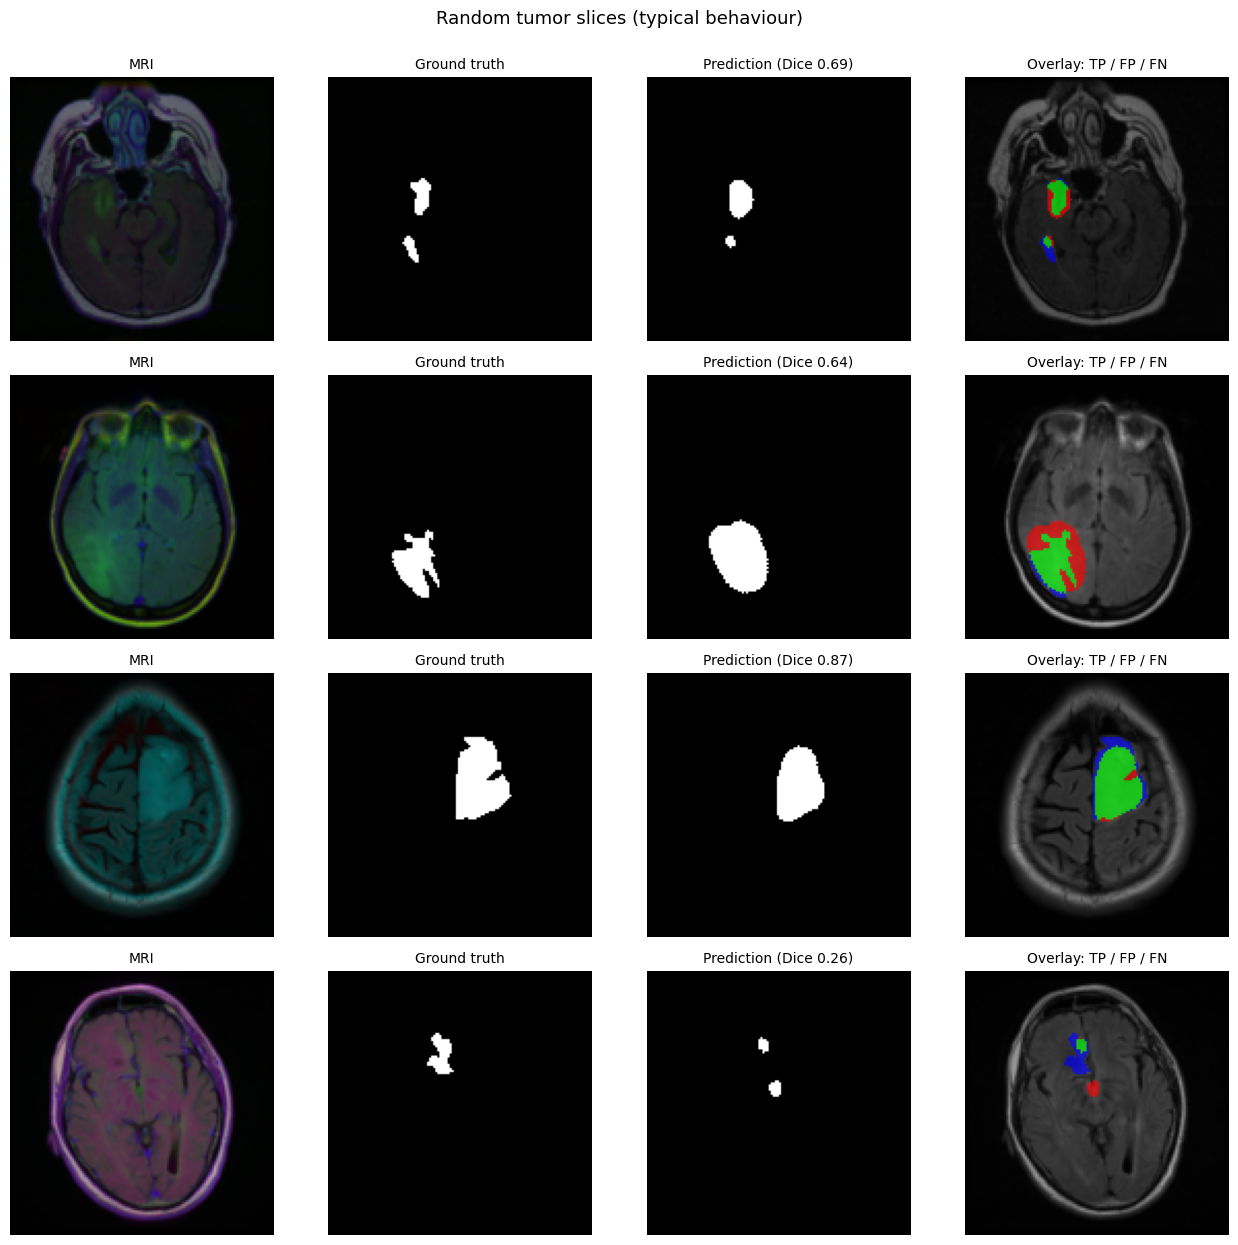

In [ ]:
def make_overlay(img_uint8, gt, pred):
    # grayscale base from the middle channel, coloured by TP / FP / FN
    g = img_uint8[1].astype(np.float32) / 255.0
    rgb = np.stack([g, g, g], axis=-1)
    for region, colour in [((gt == 1) & (pred == 1), (0, 1, 0)),     # TP green
                           ((gt == 0) & (pred == 1), (1, 0, 0)),     # FP red
                           ((gt == 1) & (pred == 0), (0, 0, 1))]:    # FN blue
        rgb[region] = 0.35 * rgb[region] + 0.65 * np.array(colour)
    return rgb


def show_cases(positions, title):
    # `positions` index into the TEST set (test_idx[k] is the global slice index)
    if len(positions) == 0:
        print(f"{title}: none found 🎉"); return
    fig, axes = plt.subplots(len(positions), 4, figsize=(13, 3.1 * len(positions)))
    axes = np.atleast_2d(axes)
    for r, k in enumerate(positions):
        g = test_idx[k]
        gt = test_masks[k, 0].numpy().astype(int)
        pred = (test_probs[k, 0] > best_thr).numpy().astype(int)
        denom = gt.sum() + pred.sum()
        d = 2 * (gt & pred).sum() / denom if denom > 0 else 1.0
        axes[r, 0].imshow(X[g].transpose(1, 2, 0));                 axes[r, 0].set_title("MRI", fontsize=10)
        axes[r, 1].imshow(gt, cmap="gray", vmin=0, vmax=1);         axes[r, 1].set_title("Ground truth", fontsize=10)
        axes[r, 2].imshow(pred, cmap="gray", vmin=0, vmax=1);       axes[r, 2].set_title(f"Prediction (Dice {d:.2f})", fontsize=10)
        axes[r, 3].imshow(make_overlay(X[g], gt, pred));            axes[r, 3].set_title("Overlay: TP / FP / FN", fontsize=10)
        for a in axes[r]: a.axis("off")
    fig.suptitle(title, y=1.0, fontsize=13)
    plt.tight_layout()
    plt.show()


pos_positions = np.where(pos.numpy())[0]
rng = np.random.default_rng(SEED)
show_cases(rng.choice(pos_positions, 4, replace=False), "Random tumor slices (typical behaviour)")

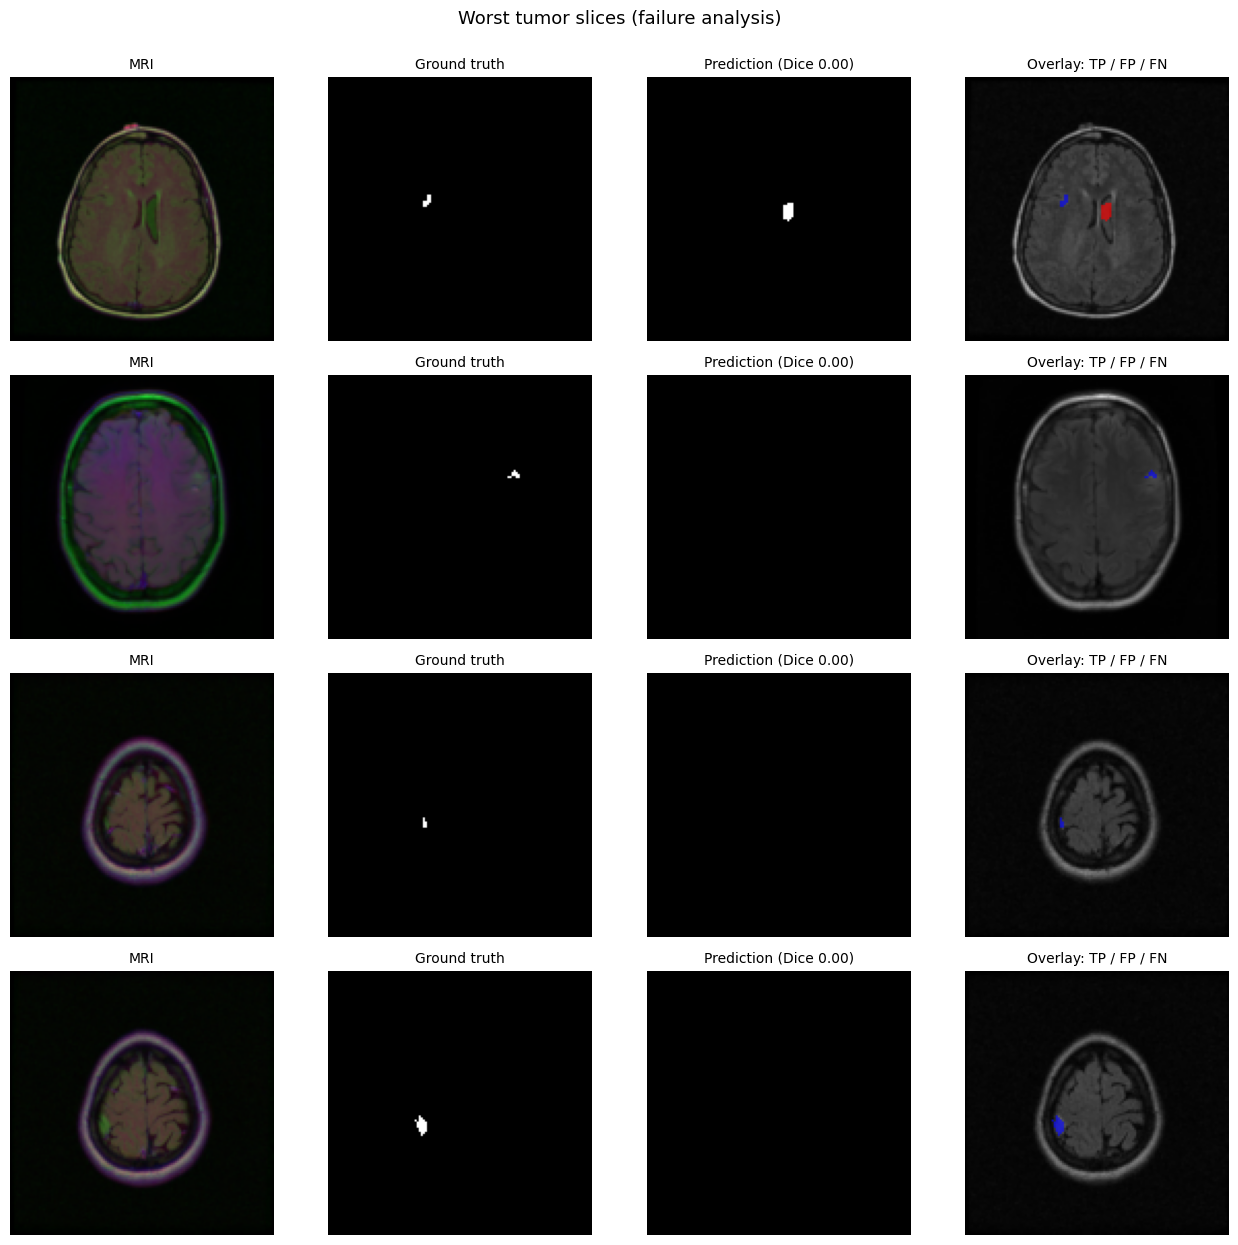

In [ ]:
# Worst tumor slices: the most instructive plots in the notebook. Look for patterns (tiny tumors? unusual anatomy?)
worst = pos_positions[np.argsort(slice_dice)[:4]]
show_cases(worst, "Worst tumor slices (failure analysis)")

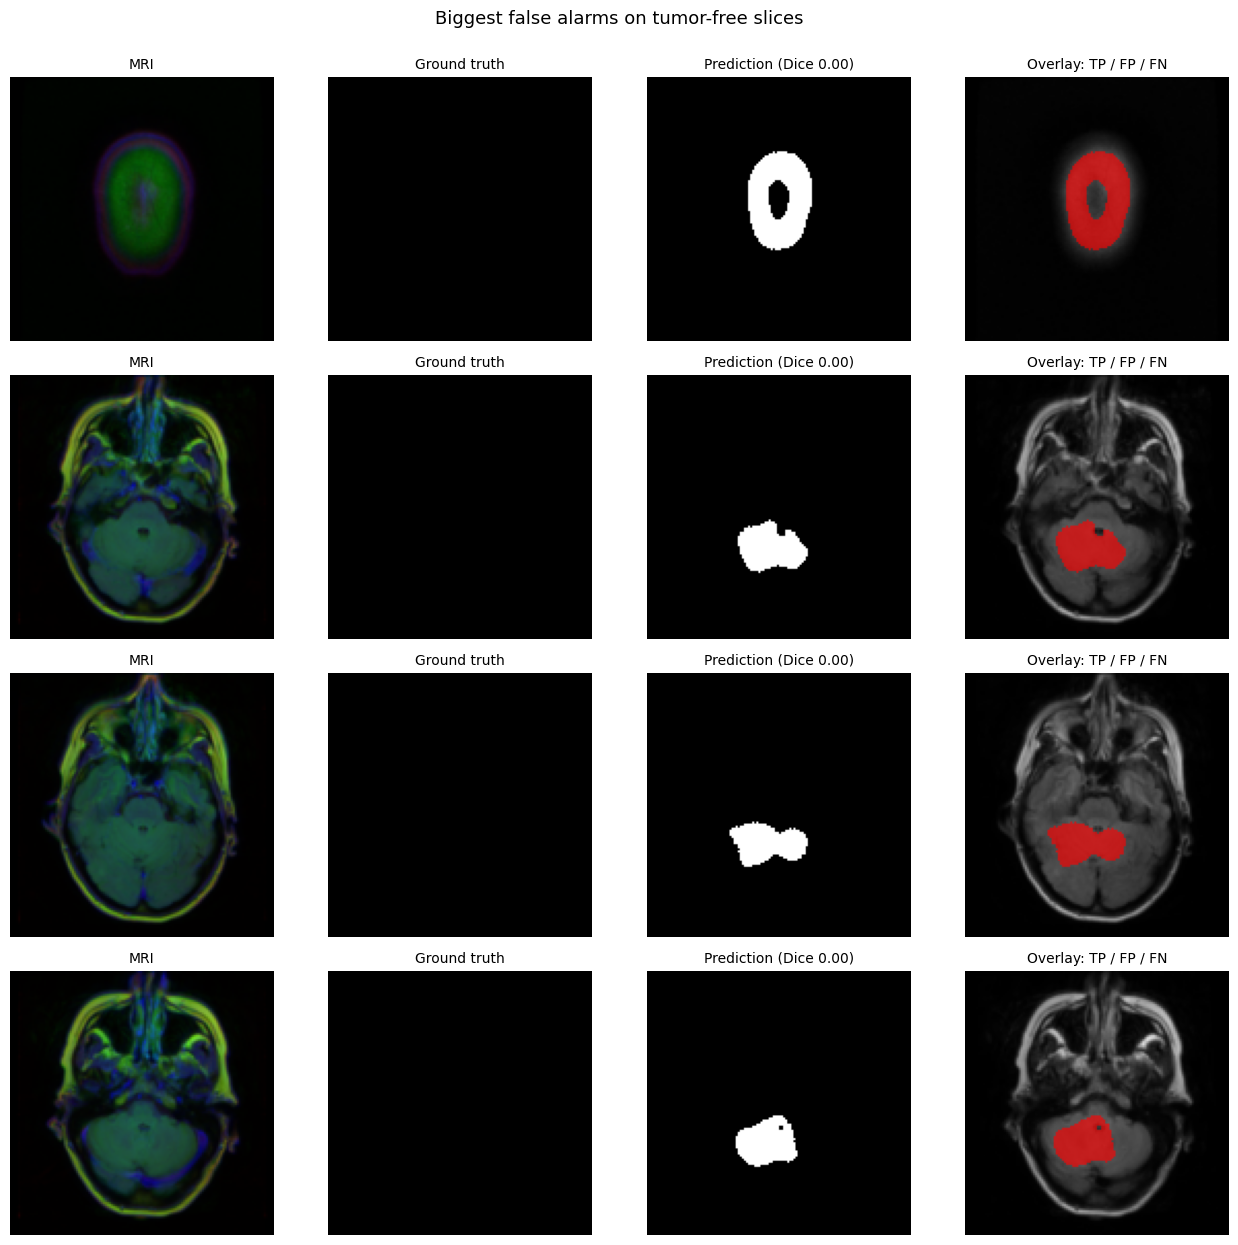

In [ ]:
# False alarms: tumor-free slices where the model hallucinates a tumor
empty_positions = np.where(~pos.numpy())[0]
empty_fp = empty_positions[np.argsort(-p_area[empty_positions].numpy())[:4]]
empty_fp = [k for k in empty_fp if p_area[k] >= MIN_AREA]
show_cases(empty_fp, "Biggest false alarms on tumor-free slices")

## 10. Saving the Model & Segmenting a New Slice

A segmentation model is just weights plus the preprocessing recipe. To use it later you need the **same normalization statistics** and the **chosen threshold**, so we save those alongside the weights.

In [ ]:
torch.save({
    "state_dict": model.state_dict(),
    "img_size": IMG_SIZE, "mean": CH_MEAN, "std": CH_STD, "threshold": best_thr,
}, "unet_brain_mri.pt")
print("Saved to unet_brain_mri.pt")

# Reload into a fresh model and segment ONE raw slice end-to-end
ckpt = torch.load("unet_brain_mri.pt", map_location=device)
reloaded = UNet(in_channels=3, n_classes=1, base=32).to(device)
reloaded.load_state_dict(ckpt["state_dict"]); reloaded.eval()

@torch.no_grad()
def segment_slice(net, img_uint8):
    # img_uint8: (3, H, W) uint8 array at the training resolution -> binary mask (H, W)
    x = eval_transform(tv_tensors.Image(torch.from_numpy(img_uint8))).as_subclass(torch.Tensor).unsqueeze(0).to(device)
    prob = torch.sigmoid(net(x).float())[0, 0].cpu().numpy()
    return (prob > ckpt["threshold"]).astype(np.uint8), prob

example = test_idx[pos_positions[0]]
mask_pred, prob_map = segment_slice(reloaded, X[example])
print("Predicted tumor pixels:", int(mask_pred.sum()), "| true tumor pixels:", int(Y[example].sum()))

Saved to unet_brain_mri.pt
Predicted tumor pixels: 229 | true tumor pixels: 123


## 🎓 Recap — What You Learned

| Concept | What it does |
|---|---|
| **Semantic segmentation** | Classifies **every pixel**; the output mask has the same height and width as the input |
| **Encoder / decoder** | Encoder downsamples for context; decoder upsamples back to full resolution for precise boundaries |
| **Skip connections** | Copy high-resolution encoder features to the decoder, restoring the detail pooling discarded |
| **`ConvTranspose2d`** | A learnable upsampling layer (stride 2 doubles height and width) |
| **Joint augmentation** | `tv_tensors.Image` + `tv_tensors.Mask`: geometric transforms hit both, photometric only the image |
| **Patient-level split** | Neighbouring slices are near-duplicates, so all slices of a patient must stay in one split |
| **BCE + Dice loss** | BCE for stable gradients, Dice to directly optimize overlap under heavy class imbalance |
| **Dice / IoU** | The right overlap metrics; pixel accuracy is meaningless when background is ~99% of pixels |
| **Threshold tuning** | Choose the probability cutoff on validation, report on test |
| **Failure analysis** | Always inspect worst cases and false alarms, not just average scores |

### 📊 What to expect
- The model should learn quickly: validation Dice usually climbs steeply in the first few epochs, then flattens.
- **Large, clear tumors** should be segmented well; **very small tumors** and tumor-free slices are where the errors concentrate (the scatter plot and the "worst cases" grid show this).
- Your exact numbers depend on which patients land in each split. With only ~17 test patients, scores are **noisy**, and differences of a point or two between runs mean little.

### ⚠️ Honest limitations
- This is a **small, single-collection research dataset** (about 110 patients from one public archive). A model trained here would be expected to degrade on scanners, protocols, and patient populations it hasn't seen.
- We **downsampled to 128×128**, which blurs small lesions. We also treat each 2-D slice independently, discarding 3-D context that a radiologist uses.
- Real clinical segmentation systems require extensive validation, regulatory review, and expert oversight. Nothing in this notebook is suitable for clinical use.

### 🧪 Try It Yourself
- **Skip-connection ablation:** train `UNet(use_skips=False)` (the `Up` blocks then receive zeros instead of the encoder features). How much does Dice drop, and how do the predicted *boundaries* change? This is the single most instructive experiment of the week.
- Compare **BCE only**, **Dice only**, and **BCE + Dice**. Which learns fastest? Which is most stable?
- Set `IMG_SIZE = 256`: does the full resolution help the small tumors enough to justify the ~4× slower training?
- Change `base=32` to `16` or `64`: how do parameter count, training time, and Dice trade off?
- Replace `ConvTranspose2d` with `nn.Upsample(scale_factor=2, mode="bilinear")` + a 1×1 conv. Do you notice checkerboard artifacts or a difference in score?
- Stack **neighbouring slices as the input channels** (e.g., slices k−1, k, k+1) to give the model 3-D context.
- Try a **pretrained encoder**: replace the U-Net's encoder with ResNet18/34 layers (as in Weeks 4–6) and keep our decoder. How much does pretraining help with ~80 training patients?
- Add **test-time augmentation**: average the predictions for the image and its horizontal flip.

Next week: we'll keep building on these vision foundations. 🚀

<div align="center">

**© 2026 Md. Mehedi Hasan. All Rights Reserved.**

</div>